<>:18: SyntaxWarning: invalid escape sequence '\E'
<>:18: SyntaxWarning: invalid escape sequence '\E'
C:\Users\frdch\AppData\Local\Temp\ipykernel_5952\1081615748.py:18: SyntaxWarning: invalid escape sequence '\E'
  im = ski.imread("FORM1\EXAM_FORM1_54331.jpg") # 2 image
C:\Users\frdch\AppData\Local\Temp\ipykernel_5952\1081615748.py:33: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  im4 = morphology.remove_small_objects(im4, min_size=100)
C:\Users\frdch\AppData\Local\Temp\ipykernel_5952\1081615748.py:35: FutureWarning: `square` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
 

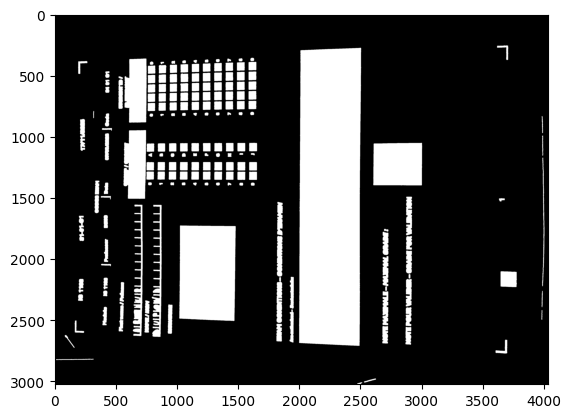

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import time
import scipy.optimize as sp
import skimage.io as ski 
import os
from skimage import color
from skimage import filters
from skimage import feature
from skimage.transform import hough_line, hough_line_peaks

import skimage
from scipy import ndimage
# import skimage.io as ski
# im = ski.imread("FORM1/EXAM_FORM1_62445.jpg")
# im = ski.imread("FORM1\EXAM_FORM1_61856.jpg")
# im = ski.imread("FORM1\EXAM_FORM1_62401.jpg") # image de reférence
im = ski.imread("FORM1\EXAM_FORM1_54331.jpg") # 2 image 
# im = ski.imread("EXAM_FORM1_54331.jpg")
# im = ski.imread("EXAM_FORM1_58220.jpg")

im_rgb = im[:, :, :3]  # on garde uniquement R, G, B
im2 = color.rgb2gray(im_rgb)

# dir(skimage.filters)
im3 = filters.sobel(im2)

from skimage import feature, morphology
from scipy.ndimage import binary_fill_holes
size = 5
seuil = filters.threshold_otsu(im3)
im4 = im3>seuil*0.7
im4 = morphology.remove_small_objects(im4, min_size=100)
im_dilate = ndimage.binary_dilation(im4, structure=np.ones((size, size)))
im_close = morphology.binary_closing(im_dilate, morphology.square(size))
im4 = binary_fill_holes(im_close)
plt.imshow(im4, cmap='gray')

188
188


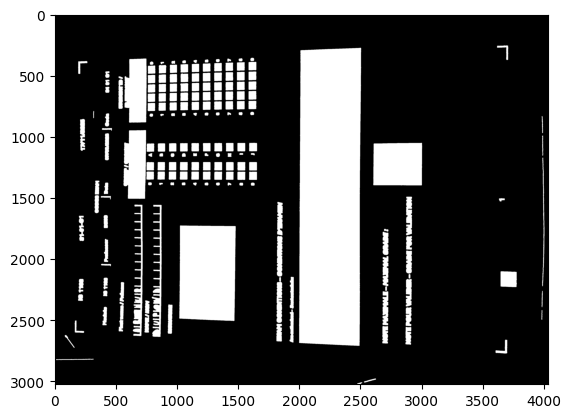

In [4]:
imlabel, nbCC   = skimage.measure.label(im4, connectivity=2, return_num= True)
regionprops= skimage.measure.regionprops(imlabel)
plt.imshow(imlabel>10**(-10), cmap='gray')
print(nbCC)
print(len(regionprops))


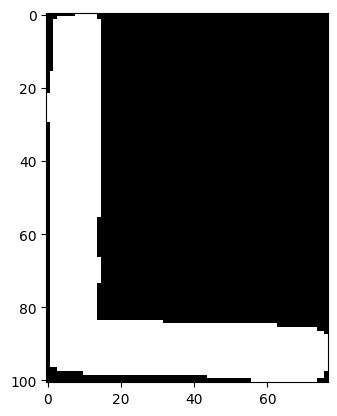

In [5]:
k = 179


min_row, min_col, max_row, max_col = regionprops[k].bbox

imtest = imlabel[min_row:max_row, min_col:max_col]

plt.imshow(imlabel[min_row:max_row, min_col:max_col] > 0, cmap='gray')


In [6]:
x,y=imtest.shape


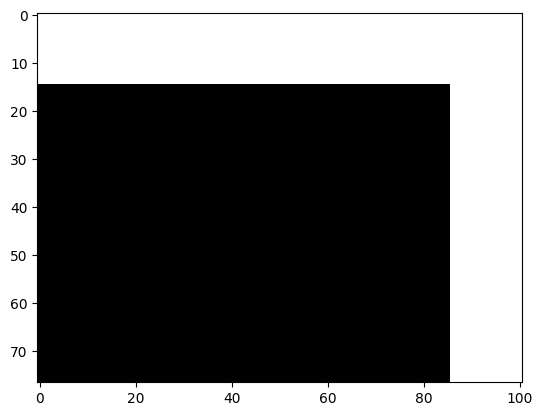

In [7]:
coins =np.ones((x, y))
const= int(min(x, y)*0.2)
coins[const:, const:] = 0
coins= np.rot90(coins, 3)
plt.imshow(coins, cmap='gray')

In [8]:
15/80

0.1875

In [9]:
print(np.corrcoef(imtest.flatten(), coins.flatten())[0, 1]
      )

-0.08933391411655389


In [10]:

bestCoinTL = []

bestCoinTR = []

bestCoinBL = []

bestCoinBR = []



# listg=[]

for k in range(len(regionprops)):

    min_row, min_col, max_row, max_col = regionprops[k].bbox
    
    pattern = imlabel[min_row:max_row, min_col:max_col] > 0
    
    dimL, diml = pattern.shape
    matCoin = np.ones((dimL, diml))
    edge = int(min(dimL, diml) * 0.20)
    matCoin[edge:, edge:] = 0


    scoreTL = np.corrcoef(matCoin.flatten(), pattern.flatten())[0, 1]
    scoreTR = np.corrcoef(np.rot90(matCoin, 3).flatten(), pattern.flatten())[0, 1]
    scoreBL = np.corrcoef(np.rot90(matCoin, 1).flatten(), pattern.flatten())[0, 1]
    scoreBR = np.corrcoef(np.rot90(matCoin, 2).flatten(), pattern.flatten())[0, 1]

    bestCoinTL.append(scoreTL)
    bestCoinTR.append(scoreTR)
    bestCoinBL.append(scoreBL)
    bestCoinBR.append(scoreBR)
    # listg.append(max(scoreTL, scoreTR, scoreBL, scoreBR))

npbestCoinTL = np.array(bestCoinTL)
npbestCoinTR = np.array(bestCoinTR)
npbestCoinBL = np.array(bestCoinBL)
npbestCoinBR = np.array(bestCoinBR)
# nplistg = np.array(listg)

sortbestCoinTL = np.argsort(npbestCoinTL)
sortbestCoinTR = np.argsort(npbestCoinTR)
sortbestCoinBL = np.argsort(npbestCoinBL)
sortbestCoinBR = np.argsort(npbestCoinBR)
# sortlistg = np.argsort(nplistg)

print("Top 4 TL scores:", sortbestCoinTL[-1:])
print("Top 4 TR scores:", sortbestCoinTR[-1:])
print("Top 4 BL scores:", sortbestCoinBL[-1:])
print("Top 4 BR scores:", sortbestCoinBR[-1:])

tabCoin = np.array([[npbestCoinTL], [npbestCoinTR], [npbestCoinBL], [npbestCoinBR]])


listTop4 = np.array([
    sortbestCoinTL[-1],
    sortbestCoinTR[-1],
    sortbestCoinBL[-1],
    sortbestCoinBR[-1]
])



# positions dans les listes triées
pos = [ -1, -1, -1, -1 ]  # TL, TR, BL, BR

while len(np.unique(listTop4)) != 4:

    values, counts = np.unique(listTop4, return_counts=True)
    doublons_values = values[counts > 1]

    for val in doublons_values:

        doublons_indices = np.where(listTop4 == val)[0]

        corMax = []

        # récupérer les scores
        for i in doublons_indices:
            if i == 0:
                corMax.append(npbestCoinTL[listTop4[i]])
            elif i == 1:
                corMax.append(npbestCoinTR[listTop4[i]])
            elif i == 2:
                corMax.append(npbestCoinBL[listTop4[i]])
            elif i == 3:
                corMax.append(npbestCoinBR[listTop4[i]])

        corMax = np.array(corMax)

        # garder le meilleur → remplacer les autres
        best = doublons_indices[np.argmax(corMax)]

        for i in doublons_indices:
            if i != best:
                pos[i] -= 1  # on descend au candidat suivant

                if i == 0:
                    listTop4[i] = sortbestCoinTL[pos[i]]
                elif i == 1:
                    listTop4[i] = sortbestCoinTR[pos[i]]
                elif i == 2:
                    listTop4[i] = sortbestCoinBL[pos[i]]
                elif i == 3:
                    listTop4[i] = sortbestCoinBR[pos[i]]
                

print("Résultat final sans doublons:", listTop4)



    
        
        



# print(npbest_coin)
# print(np.max(npbestCoin))


Top 4 TL scores: [11]
Top 4 TR scores: [11]
Top 4 BL scores: [184]
Top 4 BR scores: [184]
Résultat final sans doublons: [ 11   0 179 184]


In [11]:

# print("\nCorrélations finales :")

# for i in range(4):
#     idx = listTop4[i]

#     if i == 0:
#         score = npbestCoinTL[idx]
#         name = "TL"
#     elif i == 1:
#         score = npbestCoinTR[idx]
#         name = "TR"
#     elif i == 2:
#         score = npbestCoinBL[idx]
#         name = "BL"
#     elif i == 3:
#         score = npbestCoinBR[idx]
#         name = "BR"

#     print(f"{name} → indice = {idx}, corrélation = {score:.3f}")


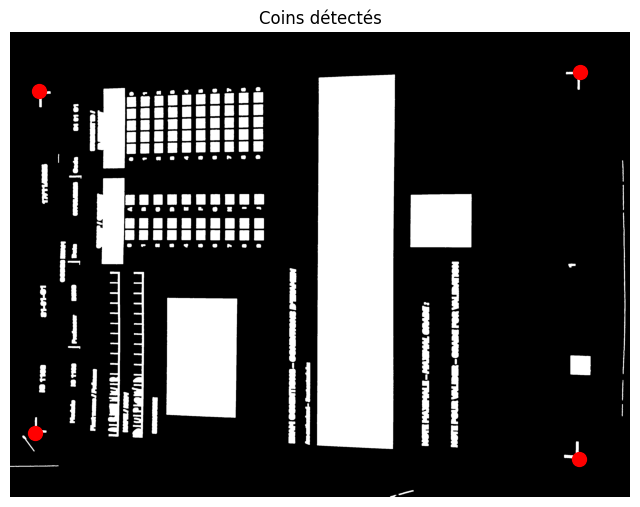

In [12]:

threshold = 0.2

points = []  # liste des coordonnées

for i in range(4):
    idx = listTop4[i]

    # récupérer score
    if i == 0:
        score = npbestCoinTL[idx]
    elif i == 1:
        score = npbestCoinTR[idx]
    elif i == 2:
        score = npbestCoinBL[idx]
    elif i == 3:
        score = npbestCoinBR[idx]

    # garder seulement si valide
    if score >= threshold:

        min_row, min_col, max_row, max_col = regionprops[idx].bbox

        if i == 0:  # TL
            pt = (min_col, min_row)
        elif i == 1:  # TR
            pt = (max_col, min_row)
        elif i == 2:  # BL
            pt = (min_col, max_row)
        elif i == 3:  # BR
            pt = (max_col, max_row)

        points.append(pt)

plt.figure(figsize=(8,8))
plt.imshow(im4, cmap='gray')

for pt in points:
    x, y = pt
    plt.plot(x, y, 'ro', markersize=10)

plt.title("Coins détectés")
plt.axis('off')
plt.show()


In [13]:

# for i in range(4):
#     idx = listTop4[i]

#     min_row, min_col, max_row, max_col = regionprops[idx].bbox
#     pattern = imlabel[min_row:max_row, min_col:max_col] > 0

#     plt.figure()
#     plt.imshow(pattern, cmap='gray')
#     plt.title(f"Coin {['TL','TR','BL','BR'][i]} (idx={idx})")
#     plt.axis('off')


A présent les signatures

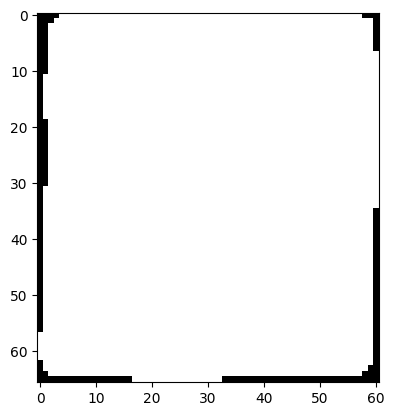

In [14]:
k = 120


min_row, min_col, max_row, max_col = regionprops[k].bbox

imtest = imlabel[min_row:max_row, min_col:max_col]

plt.imshow(imlabel[min_row:max_row, min_col:max_col] > 0, cmap='gray')

360822
462
781
150


Text(0.5, 1.0, 'Plus grande région')

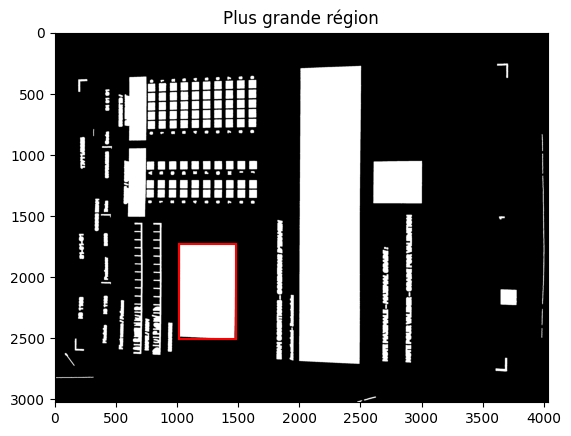

In [15]:
dimMax= 0 
l=0
L=0
i=0
for k in range(len(regionprops)):

    min_row, min_col, max_row, max_col = regionprops[k].bbox
    
    pattern = imlabel[min_row:max_row, min_col:max_col] > 0
    
    dimL, diml = pattern.shape
    if dimL*diml > dimMax and dimL<=3*diml and diml<=3*dimL:
        dimMax = dimL*diml
        l=diml
        L=dimL
        i=k
print(dimMax)
print(l)
print(L)
print(i)
min_row, min_col, max_row, max_col = regionprops[i].bbox

plt.imshow(im4, cmap='gray')
plt.plot([min_col, max_col], [min_row, min_row], 'r-')  # ligne du haut
plt.plot([min_col, max_col], [max_row, max_row], 'r-')  # ligne du bas
plt.plot([min_col, min_col], [min_row, max_row], 'r-')  # ligne de gauche
plt.plot([max_col, max_col], [min_row, max_row], 'r-')  # ligne de droite
plt.title("Plus grande région")

83


Text(0.5, 1.0, 'Régions denses et proches du carré')

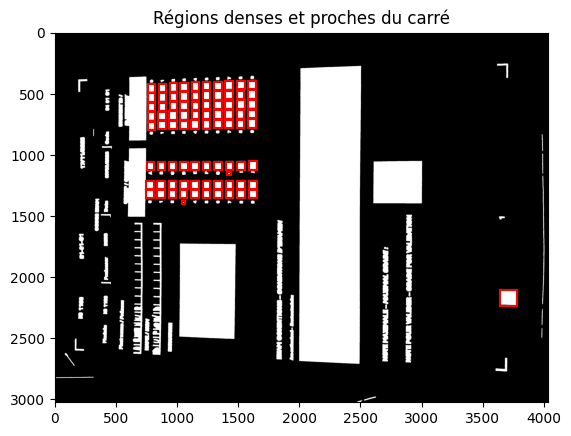

In [40]:
dimMax= []
l=0
L=0
i=0
for k in range(len(regionprops)):

    min_row, min_col, max_row, max_col = regionprops[k].bbox
    
    pattern = imlabel[min_row:max_row, min_col:max_col] > 0
    
    dimL, diml = pattern.shape
    size = dimL*diml
    nbones = np.sum(pattern)
    density = nbones / (dimL * diml)
    if density > 0.9 and abs(1-dimL/diml) < 0.2:  # Example threshold, adjust as needed
        dimMax.append([k, size])
case = np.array(dimMax)
median_size = np.median(case[:, 1])
for k, size in dimMax:
    if not abs(size - median_size) < 0.1*median_size:  # Garder les régions proches de la taille médiane   
            dimMax.remove([k, size])    
print(len(dimMax))
plt.imshow(im4, cmap='gray')
for k, size in dimMax:
    min_row, min_col, max_row, max_col = regionprops[k].bbox
    plt.plot([min_col, max_col], [min_row, min_row], 'r-')  # ligne du haut
    plt.plot([min_col, max_col], [max_row, max_row], 'r-')  # ligne du bas
    plt.plot([min_col, min_col], [min_row, max_row], 'r-')  # ligne de gauche
    plt.plot([max_col, max_col], [min_row, max_row], 'r-')  # ligne de droite
plt.title("Régions denses et proches du carré")


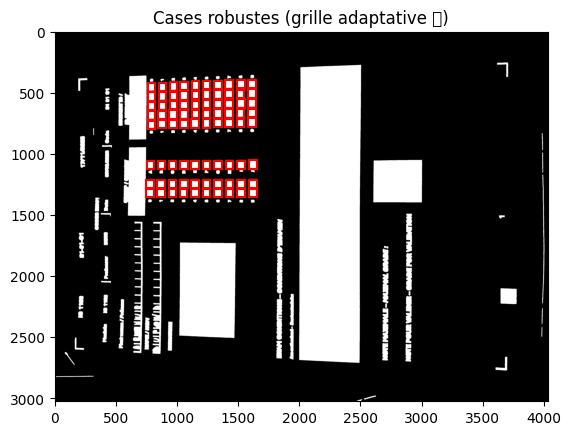

In [45]:

# --- 1. Filtrage initial (densité + forme) ---
dimMax = []

for k in range(len(regionprops)):

    min_row, min_col, max_row, max_col = regionprops[k].bbox
    
    pattern = imlabel[min_row:max_row, min_col:max_col] > 0
    
    dimL, diml = pattern.shape
    size = dimL * diml
    nbones = np.sum(pattern)
    density = nbones / size
    
    ratio = dimL / diml

    if density > 0.9 and 0.8 < ratio < 1.25:
        dimMax.append([k, size])

# --- 2. Filtre taille (relatif) ---
case = np.array(dimMax)
median_size = np.median(case[:, 1])

dimMax = [x for x in dimMax if abs(x[1] - median_size) < 0.15 * median_size]

# --- 3. Centres ---
centers = []
for k, size in dimMax:
    min_row, min_col, max_row, max_col = regionprops[k].bbox
    cx = (min_col + max_col) / 2
    cy = (min_row + max_row) / 2
    centers.append((k, cx, cy, size))

centers_xy = np.array([(cx, cy) for (_, cx, cy, _) in centers])

# --- 4. Distance typique ---
D = np.sqrt(
    (centers_xy[:, None, 0] - centers_xy[None, :, 0])**2 +
    (centers_xy[:, None, 1] - centers_xy[None, :, 1])**2
)

distances = D[D > 0]
d_typical = np.median(distances)

# --- 5. Filtrage par cohérence de grille ---
filtered = []

for i in range(len(centers)):
    k, cx, cy, size = centers[i]
    
    dists = D[i]
    
    neighbors = np.sum(
        (dists > 0.7 * d_typical) &
        (dists < 1.3 * d_typical)
    )
    
    if neighbors >= 3:
        filtered.append((k, size))

# --- 6. Affichage ---
plt.imshow(im4, cmap='gray')

for k, size in filtered:
    min_row, min_col, max_row, max_col = regionprops[k].bbox
    
    plt.plot([min_col, max_col], [min_row, min_row], 'r-')
    plt.plot([min_col, max_col], [max_row, max_row], 'r-')
    plt.plot([min_col, min_col], [min_row, max_row], 'r-')
    plt.plot([max_col, max_col], [min_row, max_row], 'r-')

plt.title("Cases robustes (grille adaptative ✅)")
plt.show()
